# When Generative AI Is Not Enough: Marketing-Aligned Multimodal Orchestration for Video Generation

> The proposed marketing-aligned multimodal orchestration system for brand personality video generation (e.g., high excitement) includes four modules: unimodal inputs, input detection agents, a video generation agent, and video inspection agents.

---

## Pipeline Overview

| Step | Module | Description |
|:----:|:-------|:------------|
| **Step 1** | Unimodal Inputs | Text, audio, and image preparation |
| **Step 2** | Input Detection Agents | Vertical strategic alignment with brand personality & horizontal semantic alignment |
| **Step 3** | Video Generation Agent | Video synthesis with voice cloning |
| **Step 4** | Video Inspection Agents | Post-generation quality inspection |

---

*Run cells sequentially from Step 1 to Step 4.*

In [1]:
# ============================================================
# Initialization
# ============================================================
import json
import warnings
from pathlib import Path
from utilities.json_utilities import to_relpath, print_modality_results

# Suppress warnings
warnings.filterwarnings("ignore", message="Unverified HTTPS request")
warnings.filterwarnings("ignore", message=".*automatic function calling.*", category=UserWarning)

# Load configuration
config_path = Path("config/config.json")
with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

# Set API keys as environment variables
api_keys = config.get("api_keys", {})
import os
for key, value in api_keys.items():
    if value:
        os.environ[key] = str(value)

# Build sample info from demo_sample config
sample_id = config.get("demo_sample", {}).get("id", "demo_mkt")
sample_info = config.get("demo_sample", {})

# Working directory for relative path conversion
work_root = Path(config.get("project", {}).get("work_dir", Path.cwd()))

# Output directory for intermediate results
run_output_dir = Path("examples/output")
run_output_dir.mkdir(parents=True, exist_ok=True)

print(f"Config loaded from {config_path}")
print(f"Sample ID: {sample_id}")
print(f"Output dir: {run_output_dir}")

Config loaded from config\config.json
Sample ID: Group1
Output dir: examples\output


# Step 1 · Unimodal Inputs

> Prepare text (video script), audio (voice sample), and image (visual reference)

In [2]:
# ============================================================
# Step 1: Unimodal Inputs
# Prepare trimodal inputs: video script (text), voice sample (audio), 
# and visual reference (image)
# ============================================================
from ai_agent.step1_unimodal_input.input_clean import normalize_unimodal_input

print("\n========== [Step 1] Unimodal Inputs ==========")
step1_result = normalize_unimodal_input(sample_info, config=config)
print("[Step 1] Done:")
print(f"  video_script: {step1_result.get('text_path')}")
print(f"  voice_sample: {sample_info.get('audio_path')}")
print(f"  visual_ref:   {step1_result.get('image_path')}")


========== [Step 1] Unimodal Inputs ==========
[Step 1] Done:
  video_script: examples\cleand_input\Group1.txt
  voice_sample: C:\Users\LCC\Downloads\Group1.wav
  visual_ref:   examples\cleand_input\Group1.jpg


In [3]:
# ============================================================
# Display Input: Video Script (text)
# Show text content with English translation if Chinese
# ============================================================
from utilities.language_utils import detect_language
from utilities.json_utilities import translate_zh_to_en

print("=" * 60)
print("[Video Script] (text)")
print("=" * 60)

text_path = step1_result.get("text_path", "")
with open(text_path, "r", encoding="utf-8") as f:
    text_content = f.read()
display_text = text_content[:500] + "..." if len(text_content) > 500 else text_content
print(display_text)

# Detect language and translate if Chinese
lang = detect_language(text_content)
if lang == "zh":
    print("\n[English Translation]:")
    print("-" * 40)
    translation = translate_zh_to_en(text_content, config)
    print(translation[:500] + "..." if len(translation) > 500 else translation)

[Video Script] (text)
大家好！快看我手上这个瓜子，瓜子仁特别大，抓一把看看，颗颗饱满，每一口都很上头，十包十六块九，买它！

[English Translation]:
----------------------------------------
Hello everyone! look at these sunflower seeds in my hand, the kernels are incredibly huge. Grab a handful, every seed is plump and every bite is absolutely addictive. Ten packs for only 16.9 yuan, get yours now!


In [4]:
# ============================================================
# Display Input: Voice Sample (audio)
# ============================================================
from IPython.display import display, Audio

print("=" * 60)
print("[Voice Sample] (audio)")
print("=" * 60)

audio_path = sample_info.get("audio_path", "")
if audio_path:
    print(f"  File: {audio_path}")
    display(Audio(audio_path))
else:
    print("  (no audio)")

[Voice Sample] (audio)
  File: C:\Users\LCC\Downloads\Group1.wav


[Visual Reference] (image)
  File: examples\cleand_input\Group1.jpg


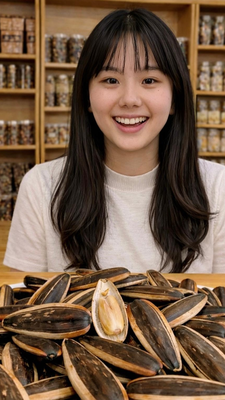

In [5]:
# ============================================================
# Display Input: Visual Reference (image)
# Height controlled at 400px, width scales proportionally
# ============================================================
from IPython.display import display
from PIL import Image

print("=" * 60)
print("[Visual Reference] (image)")
print("=" * 60)

image_path = step1_result.get("image_path", "")
if image_path:
    print(f"  File: {image_path}")
    img = Image.open(image_path)
    # Resize to height 400px, width scales proportionally
    target_height = 400
    ratio = target_height / img.height
    new_size = (int(img.width * ratio), target_height)
    img = img.resize(new_size, Image.Resampling.LANCZOS)
    display(img)
else:
    print("  (no image)")

# Step 2 · Input Detection Agents

## 2.1 Vertical Strategic Alignment with Brand Personality

> Detect whether trimodal inputs all express high excitement using Gemini (four pillars: up-to-date, imaginative, spirited, daring; Aaker, 1997)

<details>
<summary>Model</summary>

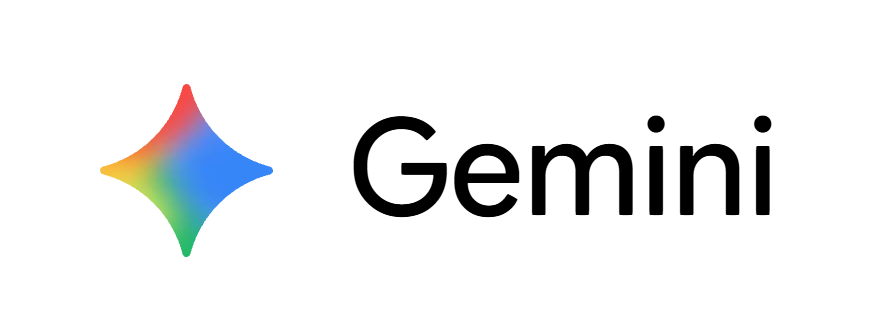

</details>

In [6]:
# ============================================================
# Step 2.1: Vertical Strategic Alignment with Brand Personality
# Use Gemini to measure excitement from four pillars:
# up-to-date, imaginative, spirited, daring (Aaker, 1997)
# Score >= 5 → high excitement; < 5 → low excitement
# ============================================================
from concurrent.futures import ThreadPoolExecutor
from ai_agent.step2_input_detection_agent.A1_theory_driven_detection.text_detection import run_text_agent
from ai_agent.step2_input_detection_agent.A1_theory_driven_detection.audio_detection import run_audio_agent
from ai_agent.step2_input_detection_agent.A1_theory_driven_detection.image_detection import run_image_agent

print("\n========== [Step 2.1] Vertical Strategic Alignment with Brand Personality ==========")
with ThreadPoolExecutor(max_workers=3) as ex:
    f_text = ex.submit(run_text_agent, step1_result, config)
    f_audio = ex.submit(run_audio_agent, step1_result, config)
    f_image = ex.submit(run_image_agent, step1_result, config)
    step2_a1_text = f_text.result()
    step2_a1_audio = f_audio.result()
    step2_a1_image = f_image.result()

step2_a1 = {"text": step2_a1_text, "audio": step2_a1_audio, "image": step2_a1_image}
print(
    f"[Step 2.1] Excitement Detection\n"
    f"  text:  {step2_a1_text.get('label')}\n"
    f"  audio: {step2_a1_audio.get('label')}\n"
    f"  image: {step2_a1_image.get('label')}"
)


========== [Step 2.1] Vertical Strategic Alignment with Brand Personality ==========
[Step 2.1] Excitement Detection
  text:  high
  audio: high
  image: high


## 2.2 Horizontal Semantic Alignment across Modalities

> Assess horizontal semantic alignment across modalities using CLIP (text-image) and CLAP (text-audio)

<details>
<summary>Model</summary>

<table>
<tr>
<td>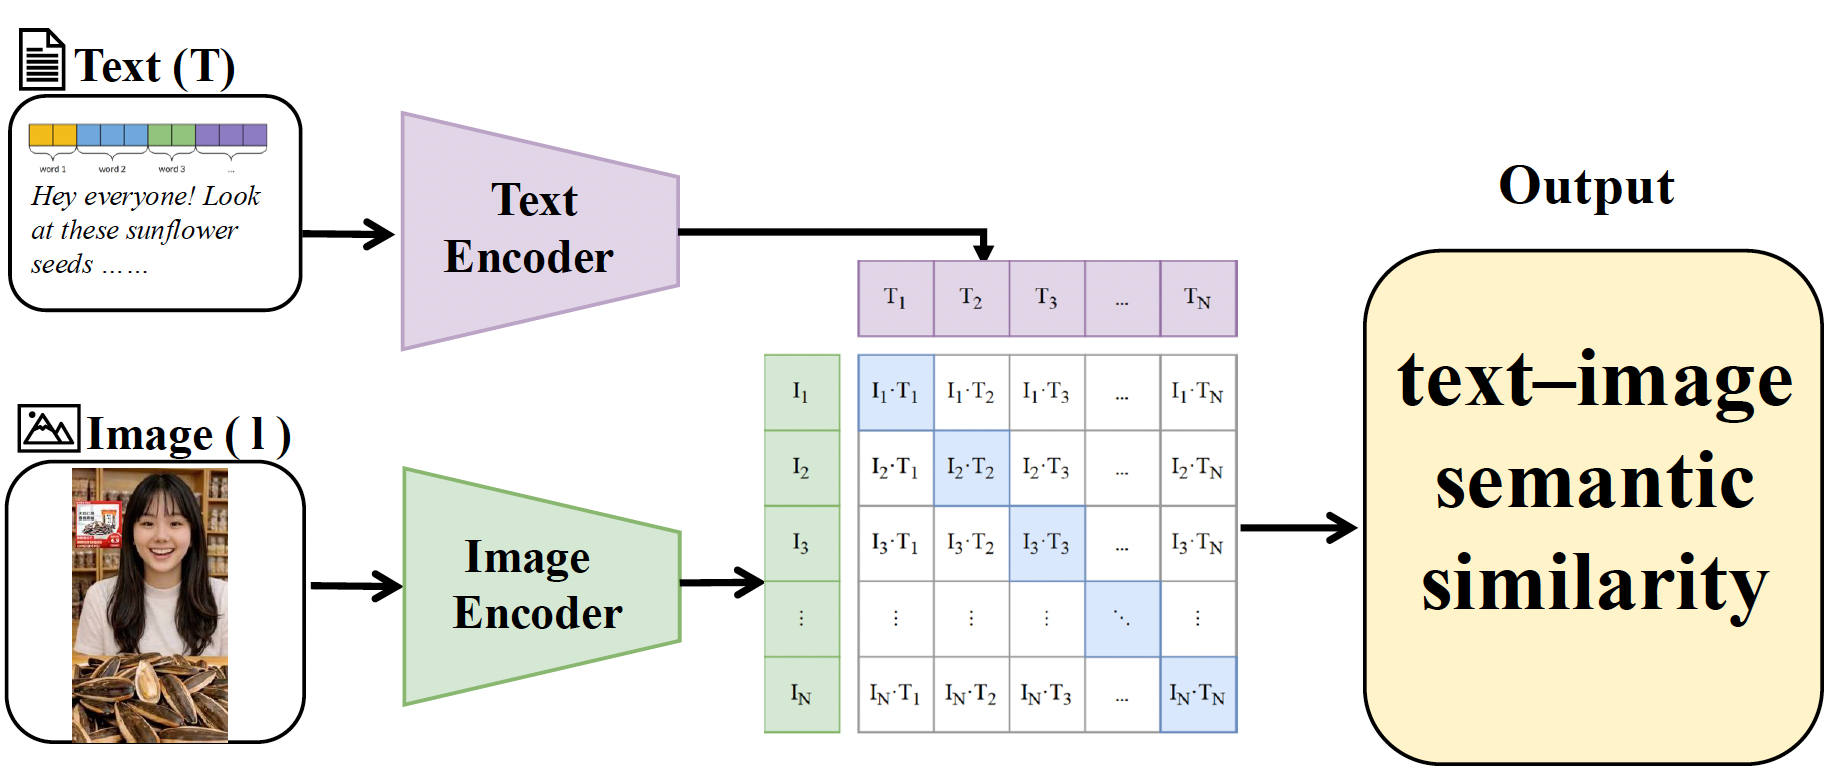</td>
<td>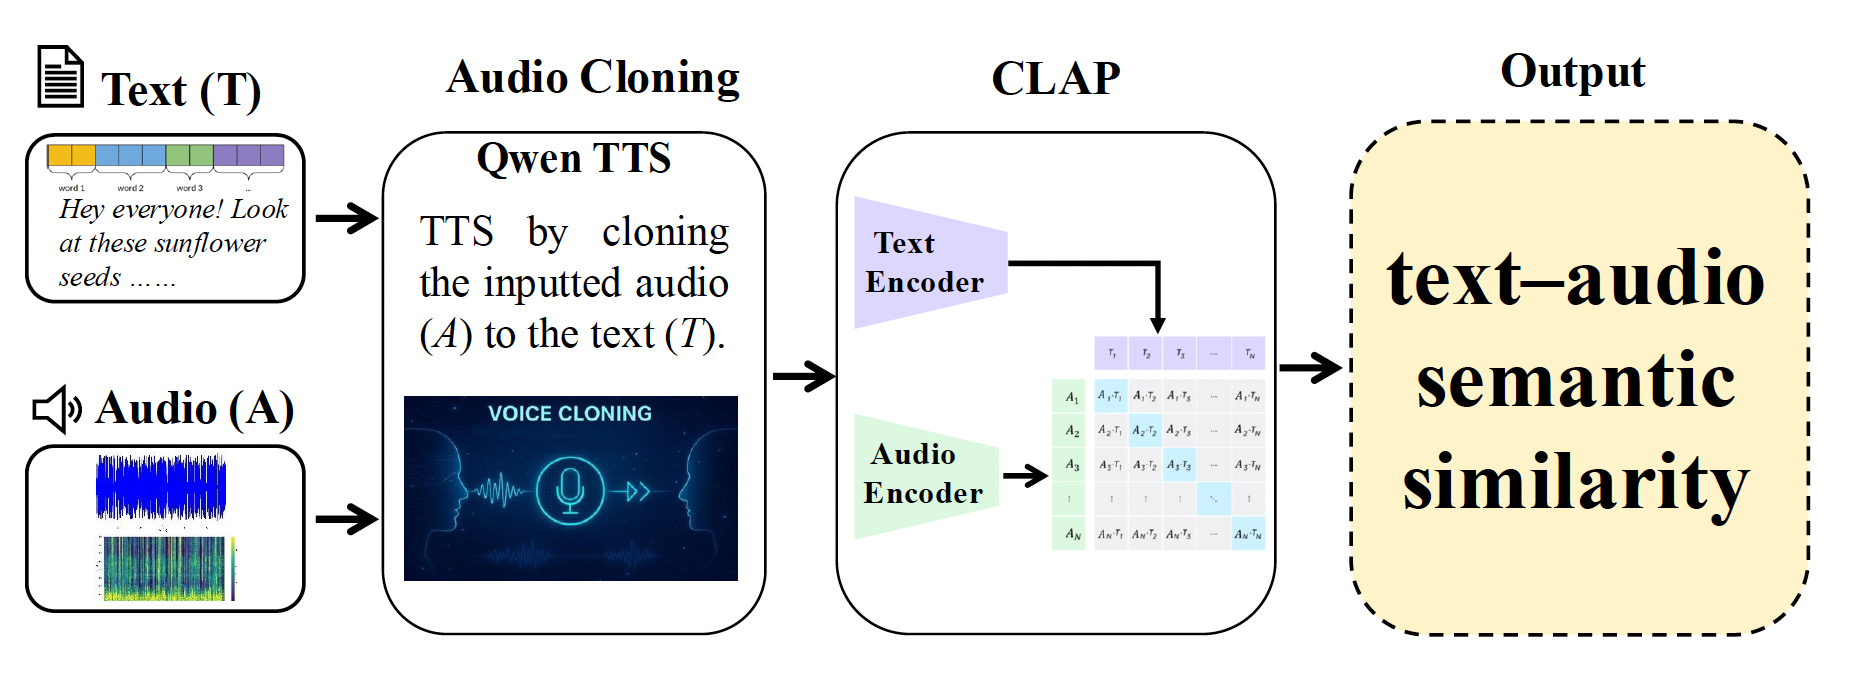</td>
</tr>
<tr>
<td align="center">CLIP (Text-Image)</td>
<td align="center">CLAP (Text-Audio)</td>
</tr>
</table>

</details>

In [7]:
# ============================================================
# Step 2.2a: Horizontal Semantic Alignment across Modalities - Text-Image (CLIP)
# Threshold: S_TI >= 0.5
# ============================================================
from ai_agent.step2_input_detection_agent.A2_data_driven_detections.clip_congruence import congruence_text_image_clip

step2_sample = dict(step1_result)

print("\n========== [Step 2.2a] Text-Image Similarity (CLIP) ==========")
clip = congruence_text_image_clip(step2_sample, config=config)
clip_score = clip.score
print(f"[CLIP] {'high' if clip_score >= 0.5 else 'low'}")


========== [Step 2.2a] Text-Image Similarity (CLIP) ==========


D:\anaconda3\envs\ai_agent\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 399/399 [00:00<00:00, 23440.07it/s]


[CLIP] high


In [8]:
# ============================================================
# Step 2.2b: Horizontal Semantic Alignment across Modalities - Text-Audio (CLAP)
# Note: Audio is cloned via Qwen TTS from voice sample + video script
# Threshold: S_TA >= 0.5
# ============================================================
from ai_agent.step2_input_detection_agent.A2_data_driven_detections.clap_congruence import congruence_text_audio_clap
from ai_agent.step2_input_detection_agent.A2_data_driven_detections.tts_clone import run_tts_clone

print("\n========== [Step 2.2b] Voice Cloning (Qwen TTS) ==========")
tts_result = run_tts_clone(step1_result, config=config)
step2_sample_for_clap = dict(step2_sample)
if bool(tts_result.get("success")) and tts_result.get("audio_path"):
    step2_sample_for_clap["tts_audio_path"] = str(tts_result.get("audio_path"))
print(f"  method: {tts_result.get('voice_clone_method')}")
print(f"  cloned_audio: {tts_result.get('audio_path')}")

print("\n========== [Step 2.2b] Text-Audio Similarity (CLAP) ==========")
clap = congruence_text_audio_clap(step2_sample_for_clap, config=config)
clap_score = clap.score
print(f"[CLAP] {'high' if clap_score >= 0.5 else 'low'}")


========== [Step 2.2b] Voice Cloning (Qwen TTS) ==========
  method: Qwen TTS
  cloned_audio: examples\cleand_input\Group1.wav

========== [Step 2.2b] Text-Audio Similarity (CLAP) ==========


Loading weights: 100%|██████████| 447/447 [00:00<00:00, 9336.46it/s]


[CLAP] high


## 2.3 Alignment Evaluation

> Pass only when both vertical strategic alignment with brand personality (all high excitement) and horizontal semantic alignment (scores ≥ 0.5) conditions are met

In [9]:
# ============================================================
# Step 2.3: Alignment Evaluation
# Pass iff: all trimodal inputs are high excitement (vertical strategic alignment with brand personality)
#          AND S_TI >= 0.5, S_TA >= 0.5 (horizontal semantic alignment)
# ============================================================
from ai_agent.step2_input_detection_agent.A3_congruence_evaluation.congruence_agent import run_congruence

step2_a2 = {"clip": clip, "clap": clap}

print("\n========== [Step 2.3] Alignment Evaluation ==========")
print("Vertical Strategic Alignment with Brand Personality")
print(f"  text:  {step2_a1_text.get('label')}")
print(f"  audio: {step2_a1_audio.get('label')}")
print(f"  image: {step2_a1_image.get('label')}")
print("Horizontal Semantic Alignment")
print(f"  S_TI (CLIP): {'high' if clip_score >= 0.5 else 'low'}")
print(f"  S_TA (CLAP): {'high' if clap_score >= 0.5 else 'low'}")

step2_a3 = run_congruence(step2_a1, step2_a2, config)
step2_result = {"a1_theory": step2_a1, "a2_data": step2_a2, "a3_congruence": step2_a3}
final_status = step2_a3.get("final", {}) if isinstance(step2_a3, dict) else {}
is_a3_pass = bool(final_status.get("is_congruence", final_status.get("is_consistent", False)))
print(f"\n[Step 2.3] {'PASS' if is_a3_pass else 'FAIL'}")


========== [Step 2.3] Alignment Evaluation ==========
Vertical Strategic Alignment with Brand Personality
  text:  high
  audio: high
  image: high
Horizontal Semantic Alignment
  S_TI (CLIP): high
  S_TA (CLAP): high

[Step 2.3] PASS


# Step 3 · Video Generation Agent

> Fuse trimodal inputs via Gemini, then replace audio with Qwen cloned voice

<details>
<summary>Model</summary>

<table>
<tr>
<td>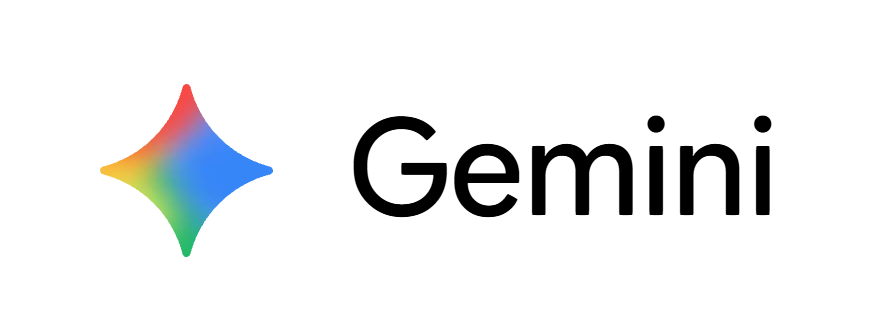</td>
<td>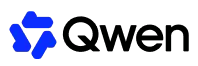</td>
</tr>
<tr>
<td align="center">Gemini Veo (Video)</td>
<td align="center">Qwen (Voice Cloning)</td>
</tr>
</table>

</details>

In [10]:
# ============================================================
# Step 3a: Video Generation (Gemini Veo)
# Fuse trimodal inputs via prompt engineering
# ============================================================
from ai_agent.step3_video_generation_agent.fusion_agent import fuse_agent

print("========== [Step 3a] Video Generation (Gemini Veo) ==========")
step3_fuse_result = fuse_agent(step1_result, config=config)
fused_video_path = str(
    ((step3_fuse_result.get("video_generation", {}) or {}).get("output_path", ""))
).strip() if isinstance(step3_fuse_result, dict) else ""
if fused_video_path:
    config.setdefault("step3_video_generation_agent", {})
    config["step3_video_generation_agent"]["input_video_path"] = fused_video_path
print(f"[Step 3a] fused_video: {fused_video_path}")

========== [Step 3a] Video Generation (Gemini Veo) ==========
[VEO] using model: veo-3.1-fast-generate-preview
[VEO] task_id=task_7MOvTdkdSSoP2badFsisOBDtPdCkJEBq, status=queued
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=completed, progress=100%
[Step 3] Attempt 1 failed: Download failed after 5 tries: 400 Client Error: Bad Request for url: https://api.apiyi.com/v1/videos/task_7MOvTdkdSSoP2badFsisOBDtPdCkJEBq/content. Retrying in 10.0s...
[VEO] using model: veo-3.1-fast-generate-preview
[VEO] task_id=task_Pcc5xb5z9ne2fHkMRXDKtt6byQ7wgB21, status=queued
[VEO] status=queued, progress=0%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=in_progress, progress=50%
[VEO] status=completed, progress=100%
[Step 3a] 

In [11]:
# ============================================================
# Step 3b: Voice Cloning Pipeline
# 1. Extract audio from Gemini video, separate BGM and voice
# 2. Clone voice from audio sample using Qwen TTS
# 3. Combine cloned voice with BGM, output final video
# ============================================================
from ai_agent.step3_video_generation_agent.voice_cloning import run_voice_cloning_pipeline

print("\n========== [Step 3b] Voice Cloning Pipeline ==========")
step3_result = run_voice_cloning_pipeline(config=config)

resolved_video_path = ""
if isinstance(step3_result, dict):
    for key in ["output_path", "video_path", "output_video_path"]:
        path = step3_result.get(key)
        if path:
            resolved_video_path = str(path)
            break

config.setdefault("step3_video_generation_agent", {})
config["step3_video_generation_agent"]["output_path"] = resolved_video_path
config["step3_video_generation_agent"]["output_path_cloned"] = resolved_video_path

print(f"[Step 3b] final_video: {to_relpath(resolved_video_path, work_root)}")


========== [Step 3b] Voice Cloning Pipeline ==========
[Step 3b] final_video: output\voice_clone\Group1_qwen_clone_tts.mp4


# Step 4 · Video Inspection Agents

## 4.0 Unimodal Extraction

> Split generated video into text (ASR), audio, and image frames

In [12]:
# ============================================================
# Step 4.0: Unimodal Extraction
# Extract text (ASR), audio, and image frames from generated video
# ============================================================
from ai_agent.step4_video_inspection_agents.B1_unimodal_extraction.extract_from_video_demo import split_video_to_unimodal

print("\n========== [Step 4.0] Unimodal Extraction ==========")
step4_generated_unimodal_info = split_video_to_unimodal(config=config)
step4_generated_unimodal_info["brand_personality"] = config.get("brand_personality", "excitement")
step4_image_paths = step4_generated_unimodal_info.get('image_path', []) or []
print("[Step 4.0] Done:")
print(f"  text (ASR):   {to_relpath(step4_generated_unimodal_info.get('text_path'), work_root)}")
print(f"  audio:        {to_relpath(step4_generated_unimodal_info.get('audio_path'), work_root)}")
print(f"  image_count:  {len(step4_image_paths)}")
for i, img_path in enumerate(step4_image_paths, start=1):
    print(f"    frame_{i}: {to_relpath(img_path, work_root)}")


========== [Step 4.0] Unimodal Extraction ==========
[Step 4.0] Done:
  text (ASR):   examples\output\asr.txt
  audio:        examples\output\audio.wav
  image_count:  8
    frame_1: examples\output\images\frame_0.png
    frame_2: examples\output\images\frame_1.png
    frame_3: examples\output\images\frame_2.png
    frame_4: examples\output\images\frame_3.png
    frame_5: examples\output\images\frame_4.png
    frame_6: examples\output\images\frame_5.png
    frame_7: examples\output\images\frame_6.png
    frame_8: examples\output\images\frame_7.png


[ASR Text] (extracted from video)
大家好，快看我手上这个瓜子，瓜子仁特别大。抓一把看看，颗颗饱满，每一口都很上头，十包16块9，买它！

[English Translation]:
----------------------------------------
Hello everyone, look at these sunflower seeds in my hand, the kernels are incredibly large. Grab a handful and take a look—every single one is plump, and every bite is super addictive. Ten packs for 16.90, buy it!

[Extracted Audio] (from video)
  File: E:\A3_computer_programs_E\A20260819_BP_AI_Agent\examples\output\audio.wav



[Extracted Frames]


frame_1,frame_2,frame_3,frame_4
frame_5,frame_6,frame_7,frame_8

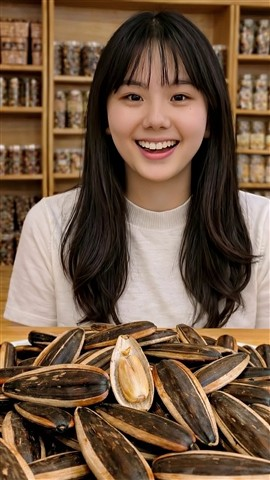
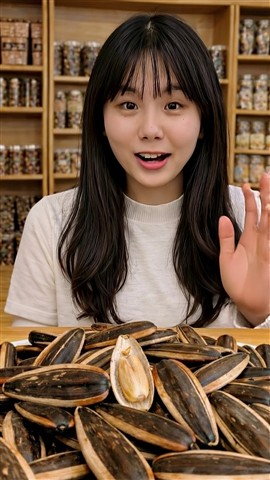
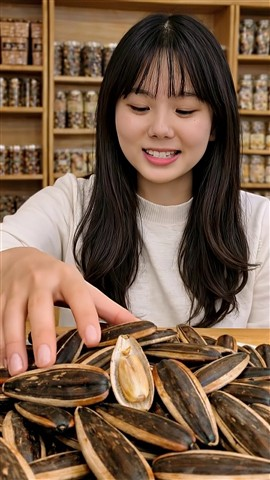
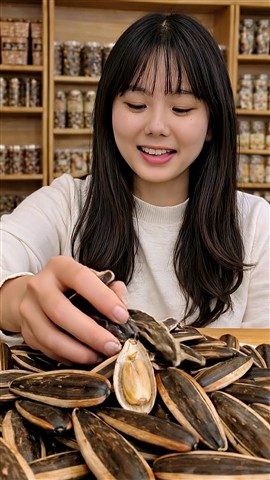
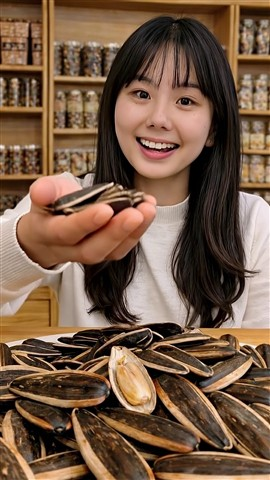
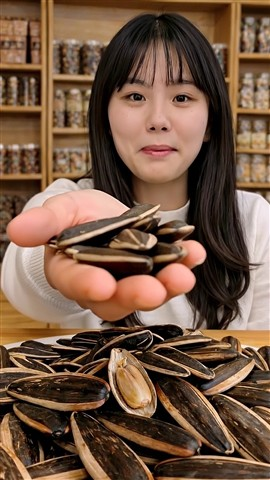
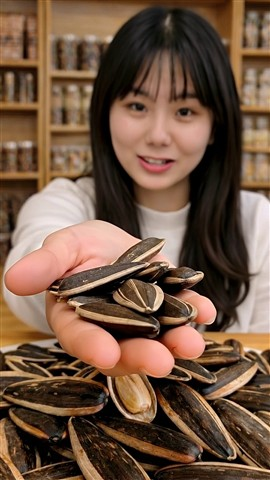
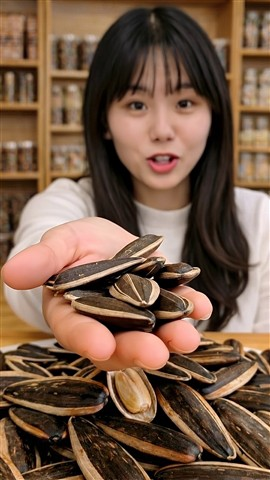

In [13]:
# ============================================================
# Display Extracted Unimodal Outputs (text, audio, frames)
# ============================================================
from utilities.display_utils import display_unimodal_outputs

display_unimodal_outputs(step4_generated_unimodal_info, step4_image_paths, config)

## 4.1 Vertical Strategic Alignment with Brand Personality

> Measure excitement scores for trimodal outputs using Gemini and compute the vertical alignment score

In [14]:
# ============================================================
# Step 4.1: Vertical Strategic Alignment with Brand Personality
# Measure excitement scores for trimodal outputs
# Compute vertical strategic alignment with brand personality across modalities
# Threshold: Vertical alignment score >= 0.5
# ============================================================
from ai_agent.step4_video_inspection_agents.B2_theory_driven_detection.text_detection import run_text_agent2
from ai_agent.step4_video_inspection_agents.B2_theory_driven_detection.audio_detection import run_audio_agent2
from ai_agent.step4_video_inspection_agents.B2_theory_driven_detection.image_detection import run_image_agent2
from ai_agent.step4_video_inspection_agents.B2_theory_driven_detection.congruence import calc_theory_congruence

print("========== [Step 4.1] Vertical Strategic Alignment with Brand Personality ==========")
b2_text = run_text_agent2(step4_generated_unimodal_info, config=config)
b2_audio = run_audio_agent2(step4_generated_unimodal_info, config=config)
b2_image = run_image_agent2(step4_generated_unimodal_info, config=config)

text_score = b2_text.get("score", 0)
audio_score = b2_audio.get("score", 0)
image_summary = b2_image.get("summary", {})
image_score = image_summary.get("mean_score", b2_image.get("score", 0))

# Calculate the vertical alignment score
congruence_result = calc_theory_congruence(text_score, audio_score, image_score)

# Store values directly
step4_b2_results = {
    "text_score": text_score,
    "audio_score": audio_score,
    "image_score": image_score,
    "std": congruence_result["std"],
    "congruence_score": congruence_result["congruence_score"],
}

print("[Step 4.1] Excitement Scores:")
print(f"  text:  {text_score:.3f}")
print(f"  audio: {audio_score:.3f}")
print(f"  image: {image_score:.3f} (mean)")
print(f"[Step 4.1] Vertical Alignment Score:")
print(f"  score:   {congruence_result['congruence_score']:.3f} (threshold >= 0.5)")

========== [Step 4.1] Vertical Strategic Alignment with Brand Personality ==========
[Step 4.1] Excitement Scores:
  text:  6.750
  audio: 8.000
  image: 6.906 (mean)
[Step 4.1] Vertical Alignment Score:
  score:   0.869 (threshold >= 0.5)


## 4.2 Horizontal Semantic Alignment across Modalities

> Assess horizontal semantic alignment across text-image, text-audio, and audio-image pairs using ImageBind

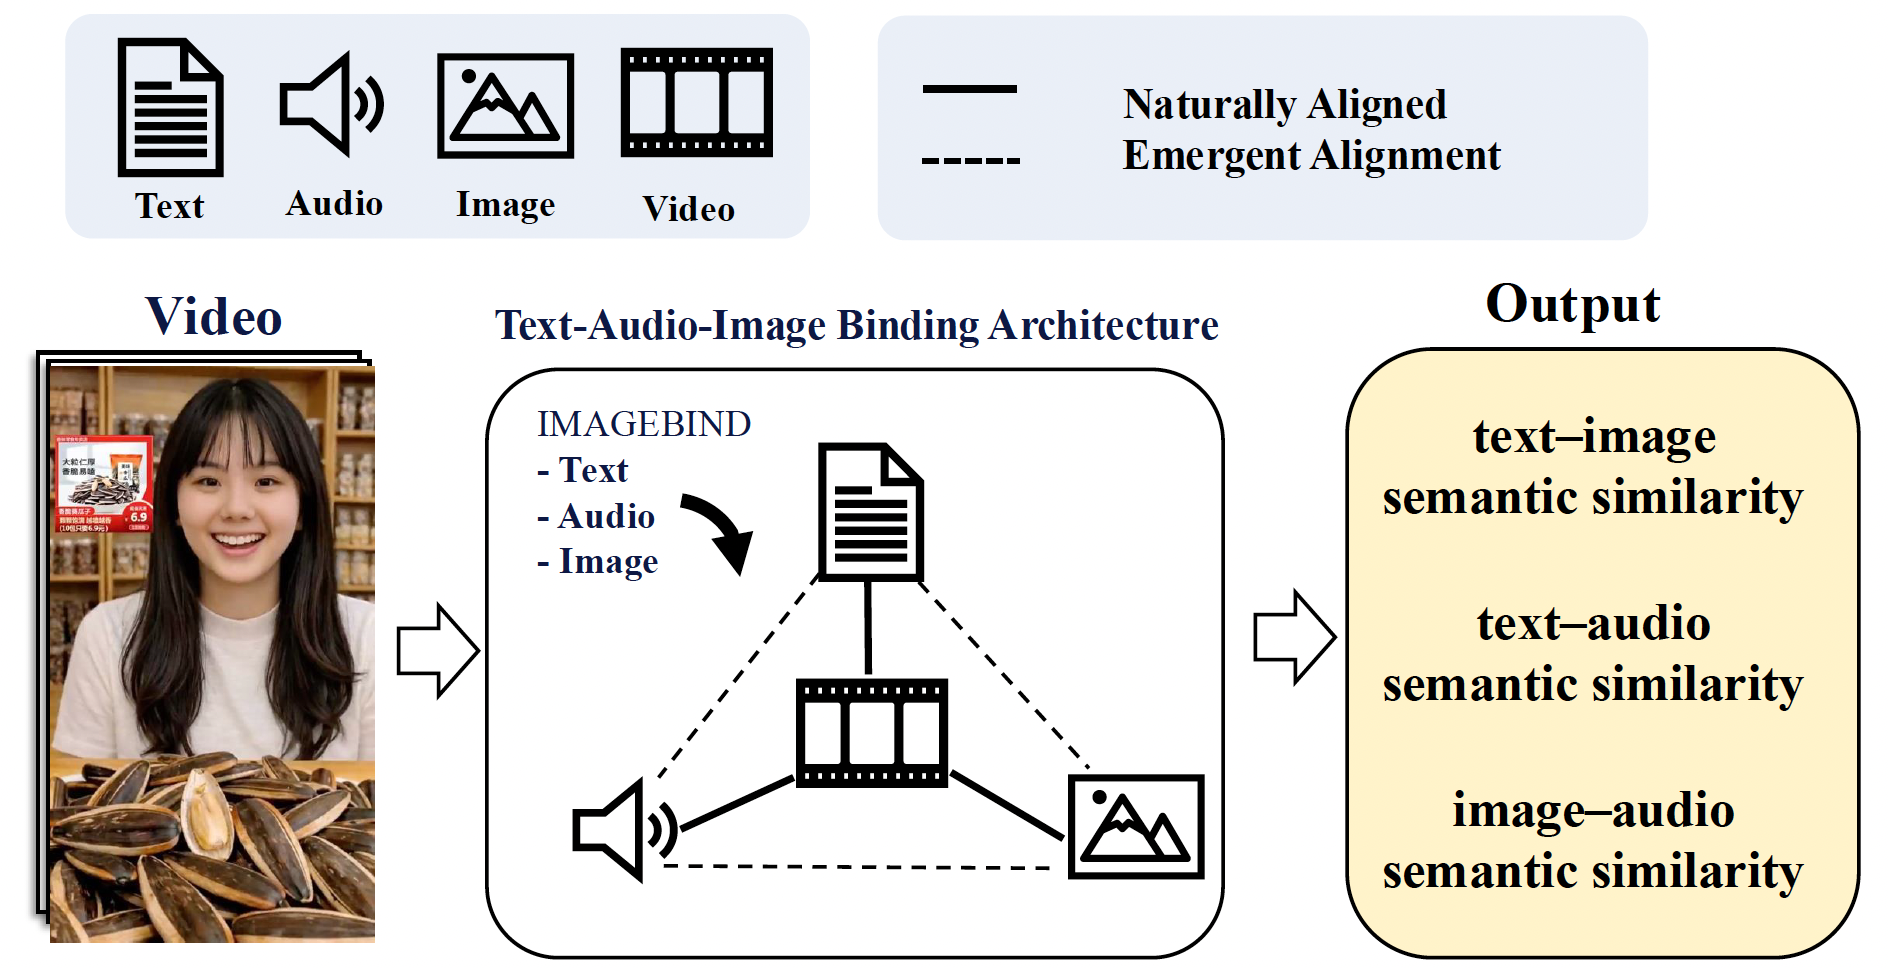

In [15]:
# ============================================================
# Step 4.2: Horizontal Semantic Alignment across Modalities (ImageBind)
# Project text, audio, image into joint embedding space
# Measure pairwise semantic similarity
# Threshold: all scores >= 0.5
# ============================================================
from ai_agent.step4_video_inspection_agents.B3_data_driven_detection.imagebind_detection import imagebind_detection

print("========== [Step 4.2] Horizontal Semantic Alignment across Modalities (ImageBind) ==========")
image_bind = imagebind_detection(step4_generated_unimodal_info, config=config)

# Store three values directly
step4_b3_results = {
    "similarity_text_audio": image_bind.similarity_text_audio,
    "similarity_text_image_mean": image_bind.similarity_text_image_mean,
    "similarity_audio_image_mean": image_bind.similarity_audio_image_mean,
}

print("[Step 4.2] ImageBind Similarity Scores:")
print(f"  S_ta (text-audio):       {step4_b3_results['similarity_text_audio']:.4f}")
print(f"  S_ti (text-image,mean):  {step4_b3_results['similarity_text_image_mean']:.4f}")
print(f"  S_ia (audio-image,mean): {step4_b3_results['similarity_audio_image_mean']:.4f}")

========== [Step 4.2] Horizontal Semantic Alignment across Modalities (ImageBind) ==========
[Step 4.2] ImageBind Similarity Scores:
  S_ta (text-audio):       0.5810
  S_ti (text-image,mean):  0.5800
  S_ia (audio-image,mean): 0.5510


## 4.3 Alignment Evaluation

> Pass only when vertical strategic alignment with brand personality (≥ 0.5) and horizontal semantic alignment (all scores ≥ 0.5) conditions are met

In [17]:
# ============================================================
# Step 4.3: Alignment Evaluation
# Pass iff: vertical strategic alignment with brand personality (score >= 0.5)
#          AND horizontal semantic alignment (S_ta, S_ti, S_ia >= 0.5)
# ============================================================
from ai_agent.step4_video_inspection_agents.B4_congruence_evaluation.congruence_agent import run_congruence2

print("========== [Step 4.3] Alignment Evaluation ==========")
step4_b4 = run_congruence2(step4_b2_results, step4_b3_results, config)
final_result = step4_b4.get("final", {})
is_pass = final_result.get("is_congruence", False)

print(f"  B2 (Vertical Strategic Alignment with Brand Personality): {step4_b4['Step4_theory_congruence']['congruence_score']:.3f} {'✅' if step4_b4['Step4_theory_congruence']['is_congruence'] else '❌'}")
print(f"  B3 (Horizontal Semantic Alignment):   ta={step4_b3_results['similarity_text_audio']:.4f}, ti={step4_b3_results['similarity_text_image_mean']:.4f}, ia={step4_b3_results['similarity_audio_image_mean']:.4f} {'✅' if step4_b4['Step4_data_congruence']['is_congruence'] else '❌'}")
print(f"  Final: {'✅ PASS' if is_pass else '❌ FAIL'}")

========== [Step 4.3] Alignment Evaluation ==========
  B2 (Vertical Strategic Alignment with Brand Personality): 0.869 ✅
  B3 (Horizontal Semantic Alignment):   ta=0.5810, ti=0.5800, ia=0.5510 ✅
  Final: ✅ PASS


## 4.4 Modification Suggestion

> Generate suggestions for inputs or video generation prompt if either alignment requirement fails

In [18]:
# ============================================================
# Step 4.4: Modification Suggestion
# If either alignment requirement fails, generate suggestions for:
# - Inputs: strengthen excitement cues in text/audio/image
# - Prompt: add mandatory entities, shift CTA earlier
# ============================================================
from ai_agent.step4_video_inspection_agents.B5_modification_suggestion.modification_suggestion import run_modification_suggestion2

step4_final_pass = bool((step4_b4.get("final", {}) or {}).get("is_congruence", False))
if step4_final_pass:
    print("\n========== [Step 4.4] Modification Suggestion ==========")
    print("[Step 4.4] ✅ Passed. Skip modification suggestion.")
    step4_b5 = {"final_pass": True, "status": "Skipped", "reason": None}
else:
    print("\n========== [Step 4.4] Modification Suggestion ==========")
    step4_b5 = run_modification_suggestion2(step4_b4, "", config=config)
    print(f"[Step 4.4] status: {step4_b5.get('status')}")


========== [Step 4.4] Modification Suggestion ==========
[Step 4.4] ✅ Passed. Skip modification suggestion.
